# Reversible jump: how many sinusoids?

The data below contain several sinusoids in white noise, and we don't
know how many. `RJPTSampler` treats the number of sinusoids `k` as a
parameter: birth and death moves add and remove sinusoids, so one run
gives the posterior on `k` together with the parameters of each sinusoid.

This notebook shows:

- a vectorized likelihood `lnlike(x, k)` for a variable number of
  components, with NaN masking;
- a prior over a variable number of sinusoids, with an amplitude floor
  and a minimum frequency gap;
- a birth density built from the data, the sinusoid analogue of an
  F-statistic proposal for galactic binaries, compared with drawing
  births from the prior;
- `component_redraw` and periodic phases (`component_periodic`);
- reading the results without being fooled by label switching.

It builds on the [quickstart](sinusoid_quickstart.ipynb) and
[vectorized likelihoods](vectorized_likelihoods.ipynb) notebooks; the
reversible-jump page of the user guide covers each option in more detail.
Besides `impulse-mcmc`, it uses `matplotlib`. The whole notebook takes
a couple of minutes to run.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np

from impulse import IndependentComponentProposal, RJPTSampler, effective_sample_size

FS, DURATION = 50.0, 20.0  # sampling rate (Hz) and length (s): 1,000 samples
t = np.arange(0.0, DURATION, 1.0 / FS)
SIGMA_TRUE = 1.0

TRUTH = np.array(
    [  # log10 amplitude, frequency (Hz), phase (rad)
        [-0.33, 0.62, 1.0],
        [-0.40, 1.07, 4.2],
        [-0.31, 1.53, 2.5],
        [-0.42, 2.11, 0.3],
        [-0.35, 2.58, 5.6],
        [-0.47, 3.04, 3.3],
        [-0.37, 3.61, 1.9],
        [-0.72, 4.17, 0.8],  # the weakest, near the detection limit
    ]
)


def signal(comps):
    # sum of sinusoids; comps is (n, 3) rows of (log10 A, f, phi)
    amp, f, phi = comps[:, :1], comps[:, 1:2], comps[:, 2:3]
    return np.sum(10.0**amp * np.sin(2 * np.pi * f * t + phi), axis=0)


rng = np.random.default_rng(2026)
data = signal(TRUTH) + SIGMA_TRUE * rng.standard_normal(t.size)
snr = 10.0 ** TRUTH[:, 0] * np.sqrt(t.size / 2) / SIGMA_TRUE
print("signal-to-noise ratios:", snr.round(1))

signal-to-noise ratios: [10.5  8.9 11.   8.5 10.   7.6  9.5  4.3]


## The data

Eight sinusoids, 20 seconds sampled at 50 Hz, white noise with
$\sigma = 1$. A sinusoid's signal-to-noise ratio is
$A\sqrt{N/2}/\sigma$: between 7.6 and 11 for seven of them, and 4.3
for the weakest, at 4.17 Hz, which is near the detection limit.

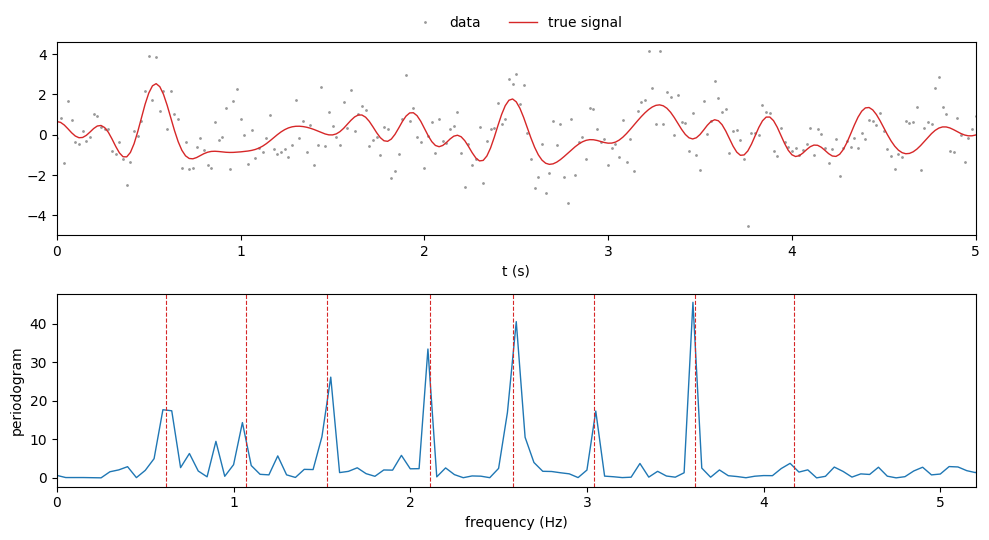

In [2]:
fig, (ax_t, ax_f) = plt.subplots(2, 1, figsize=(10, 5.5))
ax_t.plot(t, data, ".", ms=2, color="0.6", label="data")
ax_t.plot(t, signal(TRUTH), color="C3", lw=1, label="true signal")
ax_t.set(xlabel="t (s)", xlim=(0, 5))
ax_t.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)

freqs = np.fft.rfftfreq(t.size, 1.0 / FS)
ax_f.plot(freqs, np.abs(np.fft.rfft(data)) ** 2 / t.size, color="C0", lw=1)
for f in TRUTH[:, 1]:
    ax_f.axvline(f, color="C3", lw=0.8, ls="--")
ax_f.set(xlabel="frequency (Hz)", ylabel="periodogram", xlim=(0, 5.2))
fig.tight_layout();

## The model

Each sinusoid has three parameters, $(\log_{10} A, f, \phi)$, and the
noise level $\sigma$ is a *shared* parameter that every model has. With
up to `K = 12` sinusoids the sampler stores each state as a padded
vector of `D = 1 + 12 × 3 = 37` parameters: $\sigma$ first, then twelve
slots of three. Slots past `k` hold NaN.

With `vectorized=True`, `lnlike(x, k)` receives a batch: `x` is
`(batch, 37)` and `k` is `(batch,)`. Inactive slots must be masked with
`np.where` before use, because `0 * NaN` is NaN.

The prior is uniform on $k \in \{0, \dots, 12\}$, on $\sigma$ and on
each sinusoid's parameters. It is a density over *numbered* slots, so it
has no $k!$ term. Two parts of it shape the posterior on `k`:

- **An amplitude floor.** $\log_{10} A$ starts at −0.75, a
  signal-to-noise ratio of 4. A sinusoid much fainter than the noise
  hardly changes the likelihood, so if the prior allowed one, extra
  faint sinusoids would cost almost nothing and the posterior would put
  most of its weight on `k` well above the number in the data (the
  pulse example in the user guide shows the same effect).
- **A minimum gap.** Two sinusoids less than $\delta = 1/T = 0.05$ Hz
  apart can share one signal between them, and none of the built-in
  moves merges two sinusoids into one, so such a pair would linger. The prior
  rules them out. That removes more prior volume the larger `k` is:
  the share of `k` uniform frequencies on a range of length
  $L = 4.9$ Hz that are all at least $\delta$ apart is
  $(1 - (k - 1)\delta / L)^k$, and `lnprior` divides by it so that
  $p(k)$ stays uniform.

In [3]:
K, P = 12, 3  # up to 12 sinusoids of (log10 A, f, phi)
N_SHARED = 1  # the noise level sigma
D = N_SHARED + K * P
LOW = np.array([-0.75, 0.1, 0.0])  # log10 A >= -0.75: signal-to-noise ratio >= 4
HIGH = np.array([0.5, 5.0, 2 * np.pi])
SIGMA_RANGE = (0.5, 2.0)
MIN_GAP = 1.0 / DURATION  # frequencies at least 0.05 Hz apart
LOG_COMPONENT_VOLUME = np.log(np.prod(HIGH - LOW))
LOG_SIGMA_PRIOR = -np.log(SIGMA_RANGE[1] - SIGMA_RANGE[0])


def lnlike(x, k):
    # x: (batch, D), k: (batch,). Slots past k are NaN, so mask before use.
    sigma = x[:, 0]
    comps = x[:, N_SHARED:].reshape(-1, K, P)
    active = np.arange(K)[None, :] < k[:, None]  # (batch, K)
    amp = np.where(active, 10.0 ** comps[..., 0], 0.0)  # inactive slots add nothing
    f = np.where(active, comps[..., 1], 0.0)
    phi = np.where(active, comps[..., 2], 0.0)
    waves = np.sin(2 * np.pi * f[..., None] * t + phi[..., None])  # (batch, K, n_t)
    residual = data - np.einsum("bk,bkt->bt", amp, waves)
    chi2 = np.einsum("bt,bt->b", residual, residual)
    return -0.5 * chi2 / sigma**2 - t.size * np.log(sigma)


def lnprior(x, k):
    # uniform on k, sigma and each component (numbered slots, no k! term), with the
    # active frequencies at least MIN_GAP apart
    sigma = x[:, 0]
    comps = x[:, N_SHARED:].reshape(-1, K, P)
    active = np.arange(K)[None, :] < k[:, None]
    inside = np.where(active[..., None], (comps >= LOW) & (comps <= HIGH), True)
    inside = inside.all(axis=(1, 2)) & (sigma >= SIGMA_RANGE[0]) & (sigma <= SIGMA_RANGE[1])
    # inactive slots get the frequencies 10, 20, ..., so they sort last and never clash
    f = np.sort(np.where(active, comps[..., 1], 10.0 * np.arange(1, K + 1)), axis=1)
    inside &= np.all(np.diff(f, axis=1) >= MIN_GAP, axis=1)
    # the share of the frequency volume the gap keeps, (1 - (k - 1) MIN_GAP / range)^k;
    # dividing by it keeps p(k) uniform
    log_kept = k * np.log1p(-(k - 1) * MIN_GAP / (HIGH[1] - LOW[1]))
    return np.where(inside, LOG_SIGMA_PRIOR - k * LOG_COMPONENT_VOLUME - log_kept, -np.inf)

The batched function should agree with a plain per-row version:

In [4]:
def lnlike_one(x, k):  # the same likelihood for one row, written plainly
    sigma, comps = x[0], x[N_SHARED:].reshape(K, P)[:k]
    residual = data - signal(comps)
    return -0.5 * residual @ residual / sigma**2 - t.size * np.log(sigma)


test_k = np.array([0, 3, 8, 12])
test_x = np.full((4, D), np.nan)
test_x[:, 0] = 1.1
for row, kk in zip(test_x, test_k):
    row[N_SHARED : N_SHARED + kk * P] = rng.uniform(LOW, HIGH, (kk, P)).ravel()
print(np.allclose(lnlike(test_x, test_k), [lnlike_one(x, kk) for x, kk in zip(test_x, test_k)]))

True


## Where new sinusoids come from

A birth proposes a new sinusoid from the *component proposal*. Drawing
from the prior always works, but here almost every prior draw has the
wrong frequency, amplitude or phase and is rejected. The proposal below
is an F-statistic analogue, built from the data: it draws the frequency
from the periodogram, fits $a_s \sin(2\pi f t) + a_c \cos(2\pi f t)$
at that frequency by linear least squares to the *residual* (the data
minus the sinusoids already in the state), draws $(a_s, a_c)$ from the
fit's Gaussian uncertainty, and converts them to
$(\log_{10} A, \phi)$, with $a_s = A\cos\phi$ and $a_c = A\sin\phi$.

Because of the residual, the density depends on the state `(x, k)`.
That is allowed: the sampler always passes the *smaller* model's state
(the current state for a birth, the state after the removal for a
death), so a birth and the death that undoes it use the same density.
The other rules:

- `logpdf` must be the exact normalized density of what `draw` returns:
  here the periodogram cell, the Gaussian, and the Jacobian
  $\ln 10 \cdot A^2$ of the map from $(\log_{10} A, \phi)$ to
  $(a_s, a_c)$;
- it must be finite wherever the prior is: mixing it half and half with
  the prior guarantees that;
- drawn phases must lie in the declared periodic interval: `np.mod`
  puts them in $[0, 2\pi]$.

A fitted draw can fall below the amplitude floor; that birth is then
rejected by the prior.

In [5]:
edges = np.linspace(LOW[1], HIGH[1], 99)  # 98 cells of 0.05 Hz = 1 / DURATION
centres = 0.5 * (edges[:-1] + edges[1:])
power = np.abs(np.exp(-2j * np.pi * centres[:, None] * t) @ data) ** 2 / t.size


def prior_draw(rng):
    return rng.uniform(LOW, HIGH)


def prior_logpdf(u):
    return -LOG_COMPONENT_VOLUME if np.all((u >= LOW) & (u <= HIGH)) else -np.inf


def linear_fit(f, residual, sigma):
    # best (a_s, a_c) for a_s sin(2 pi f t) + a_c cos(2 pi f t), and their covariance
    design = np.stack([np.sin(2 * np.pi * f * t), np.cos(2 * np.pi * f * t)], axis=1)
    normal = design.T @ design
    return np.linalg.solve(normal, design.T @ residual), sigma**2 * np.linalg.inv(normal)


class PeriodogramBirths:
    # With probability mix: frequency from the periodogram, then (a_s, a_c) from the
    # least-squares fit at that frequency to the residual (data minus the sinusoids in
    # x), converted to (log10 A, phase). Otherwise: the prior. (x, k) is always the
    # smaller model's state; logpdf is the exact normalized density of what draw returns.

    def __init__(self, edges, weights, mix=0.5):
        self.edges = edges
        self.cell_prob = weights / weights.sum()
        self.log_cell_density = np.log(self.cell_prob / np.diff(edges))
        self.mix = mix

    def fit(self, f, x, k):
        residual = data - signal(x[N_SHARED : N_SHARED + k * P].reshape(k, P))
        return linear_fit(f, residual, x[0])  # x[0] is sigma

    def draw(self, rng, x, k):
        if rng.random() >= self.mix:
            return prior_draw(rng)
        cell = rng.choice(self.cell_prob.size, p=self.cell_prob)
        f = rng.uniform(self.edges[cell], self.edges[cell + 1])
        mean, cov = self.fit(f, x, k)
        a_s, a_c = mean + np.linalg.cholesky(cov) @ rng.standard_normal(2)
        phase = np.mod(np.arctan2(a_c, a_s), 2 * np.pi)  # in [0, 2 pi], as declared
        return np.array([np.log10(np.hypot(a_s, a_c)), f, phase])

    def logpdf(self, u, x, k):
        log_amp, f, phase = u
        if not self.edges[0] <= f <= self.edges[-1]:
            return -np.inf  # neither part draws a frequency outside the prior range
        cell = min(np.searchsorted(self.edges, f, side="right") - 1, self.cell_prob.size - 1)
        mean, cov = self.fit(f, x, k)
        amp = 10.0**log_amp
        d = amp * np.array([np.cos(phase), np.sin(phase)]) - mean
        log_fit = (
            self.log_cell_density[cell]
            - 0.5 * d @ np.linalg.solve(cov, d)
            - np.log(2 * np.pi * np.sqrt(np.linalg.det(cov)))
            + np.log(np.log(10.0) * amp**2)  # Jacobian of (log10 A, phase) -> (a_s, a_c)
        )
        return np.logaddexp(np.log(self.mix) + log_fit, np.log(1 - self.mix) + prior_logpdf(u))


periodogram_births = PeriodogramBirths(edges, power)
prior_births = IndependentComponentProposal(prior_draw, prior_logpdf)

## Run

Besides birth/death, `component_redraw` replaces one random sinusoid
with a fresh draw from the component proposal, which lets a sinusoid
jump straight to another periodogram peak. `component_periodic`
marks parameter 2 (the phase) of every sinusoid as periodic.

In [6]:
def make_sampler(component_proposal, outdir):
    return RJPTSampler(
        n_shared=N_SHARED,
        n_component=P,
        max_components=K,
        lnlike=lnlike,
        lnprior=lnprior,
        vectorized=True,
        component_proposal=component_proposal,
        component_periodic={2: 2 * np.pi},  # the phase of every sinusoid
        component_redraw_weight=20,
        ntemps=8,
        seed=1,
        outdir=outdir,
        verbose=False,
    )


x0 = np.zeros(D)
x0[0] = 1.5  # noise level; the run starts with no sinusoids (initial_k=0)

In [7]:
N_ITER, BURN = 100_000, 20_000
sampler = make_sampler(periodogram_births, "chains_rj")
start = time.perf_counter()
sampler.sample(x0, num_iterations=N_ITER, initial_k=0)
print(f"{N_ITER:,} iterations in {time.perf_counter() - start:.0f} s")

100,000 iterations in 82 s


## How many sinusoids?

`load_chain()` returns `k` alongside the padded samples.

p(k): {7: 0.593, 8: 0.344, 9: 0.06, 10: 0.003}
moves between 7 and 8 after burn-in: 1833
cold chain first reaches k = 7 at iteration 194


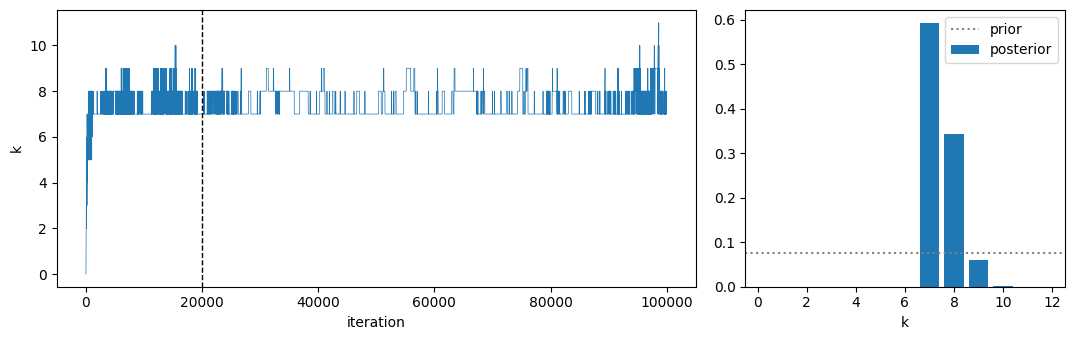

In [8]:
chain = sampler.load_chain()
k_cold = chain["k"][0]
ks = k_cold[BURN:]
p_k = np.bincount(ks, minlength=K + 1) / ks.size

fig, (ax_trace, ax_pk) = plt.subplots(
    1, 2, figsize=(11, 3.5), gridspec_kw={"width_ratios": [2, 1]}
)
ax_trace.plot(k_cold, lw=0.5)
ax_trace.axvline(BURN, color="k", ls="--", lw=1)
ax_trace.set(xlabel="iteration", ylabel="k")
ax_pk.bar(np.arange(K + 1), p_k, color="C0", label="posterior")
ax_pk.axhline(1 / (K + 1), color="0.5", ls=":", label="prior")
ax_pk.set(xlabel="k", xlim=(-0.5, K + 0.5))
ax_pk.legend()
fig.tight_layout()

print("p(k):", {k: round(float(p), 3) for k, p in enumerate(p_k) if p > 0.001})
moves_7_8 = np.sum(((ks[:-1] == 7) & (ks[1:] == 8)) | ((ks[:-1] == 8) & (ks[1:] == 7)))
print("moves between 7 and 8 after burn-in:", moves_7_8)
print("cold chain first reaches k = 7 at iteration", np.argmax(k_cold == 7))

The cold chain reaches `k = 7` at iteration 194, long before the
burn-in ends. After burn-in the posterior puts 0.593 on `k = 7` and
0.344 on `k = 8`, 0.937 together, and the rest on 9 and 10. The chain
moved between 7 and 8 1,833 times, but in bursts, with long stretches
at `k = 7` in between (see the trace), so successive values of `k` are
strongly correlated and these probabilities are uncertain by a few
hundredths (see the effective sample size below).

## Which frequencies? Beware label switching

Slot 0 in one sample need not be the same sinusoid as slot 0 in the
next: births insert at random positions, and nothing in the posterior
tells the slots apart. Per-slot traces and means are therefore
meaningless. Summaries that ignore the labels are safe, such as the
distribution of *all* active frequencies, pooled over slots:

0.62 Hz: present in 100.0% of samples
1.07 Hz: present in 100.0% of samples
1.53 Hz: present in 100.0% of samples
2.11 Hz: present in 100.0% of samples
2.58 Hz: present in 100.0% of samples
3.04 Hz: present in 99.6% of samples
3.61 Hz: present in 100.0% of samples
4.17 Hz: present in 21.6% of samples
samples with k = 8 that contain the 4.17 Hz sinusoid: 48%


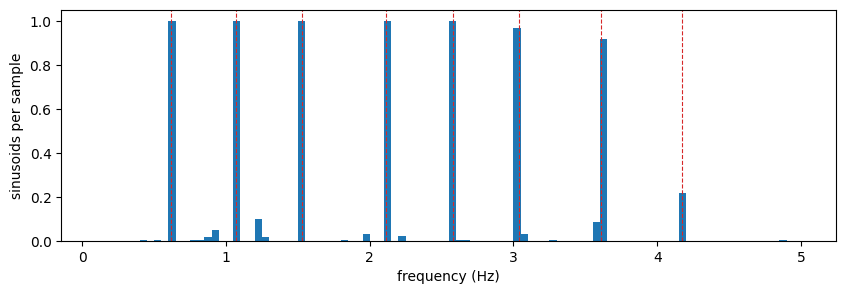

In [9]:
comps = chain["components"][0, BURN:]  # (n, K, 3), NaN past k
active_f = comps[..., 1][~np.isnan(comps[..., 1])]

fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(
    active_f,
    bins=edges,  # the 0.05 Hz periodogram cells
    weights=np.full(active_f.size, 1 / len(comps)),
    color="C0",
)
for f in TRUTH[:, 1]:
    ax.axvline(f, color="C3", lw=0.8, ls="--")
ax.set(xlabel="frequency (Hz)", ylabel="sinusoids per sample");

for f in TRUTH[:, 1]:
    present = np.any(np.abs(comps[..., 1] - f) < 0.02, axis=1)
    print(f"{f:.2f} Hz: present in {present.mean():.1%} of samples")
weakest = np.any(np.abs(comps[..., 1] - TRUTH[7, 1]) < 0.02, axis=1)
print(f"samples with k = 8 that contain the {TRUTH[7, 1]} Hz sinusoid: {weakest[ks == 8].mean():.0%}")

The seven loud sinusoids are present in at least 99.6% of the samples
after burn-in, the 4.17 Hz one in 21.6%. (The bars just below 3.61 Hz and just above
3.04 Hz are those two sinusoids: their frequencies fall on both sides of
a cell edge.) Only 48% of the samples with `k = 8` contain the 4.17 Hz
sinusoid, though. In the others the eighth sinusoid sits where the data
have only noise: the other small bars, mainly near 0.9, 1.25 and
1.95 Hz, where the periodogram above has small noise peaks. The weight
on `k = 8` is shared between the weakest sinusoid and noise peaks that
one more sinusoid can fit.

The shared parameter has no labelling problem, and neither does `k`, so
their effective sample sizes are meaningful:

In [10]:
sigma = chain["shared"][0, BURN:, 0]
print(f"noise sigma: {sigma.mean():.3f} +/- {sigma.std():.3f}   (true {SIGMA_TRUE})")
ess = effective_sample_size(np.column_stack([sigma, ks.astype(float)]))
print("effective sample size of sigma and k:", ess.round(0))

noise sigma: 1.035 +/- 0.021   (true 1.0)


effective sample size of sigma and k: [179.  86.]


The noise level comes out at 1.035 ± 0.021 against a true 1.0. Both
effective sample sizes are far below the 80,000 samples after burn-in.
With 86 effective samples of `k`, $p(k = 8) = 0.344$ has a standard
error of about $\sqrt{0.344 \cdot 0.656 / 86} \approx 0.05$; a longer
run would pin it down further.

## Reconstructed signal

Signals from 200 posterior draws, each with its own `k`:

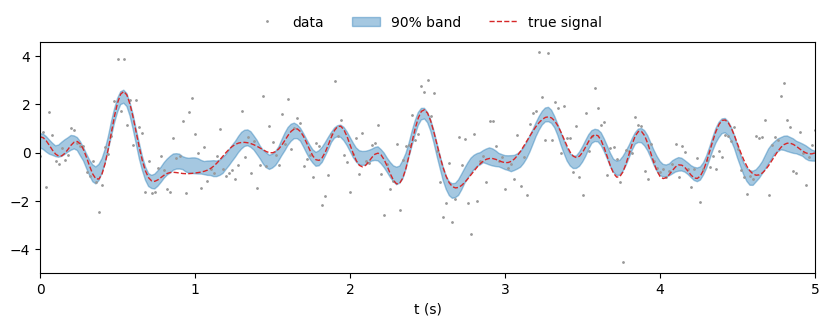

In [11]:
picks = np.random.default_rng(3).choice(len(comps), 200)
models = np.array([signal(comps[i][: ks[i]]) for i in picks])
lo, hi = np.percentile(models, [5, 95], axis=0)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, data, ".", ms=2, color="0.6", label="data")
ax.fill_between(t, lo, hi, color="C0", alpha=0.4, label="90% band")
ax.plot(t, signal(TRUTH), color="C3", lw=1, ls="--", label="true signal")
ax.set(xlabel="t (s)", xlim=(0, 5))
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False);

## Sampler health

Acceptance rates per move, summed over temperatures (`birth_death`
is reported as `birth` and `death`), and swap rates between
neighbouring temperatures:

In [12]:
for name, report in sampler.proposal_acceptance_rates().items():
    print(f"{name:>17}: {report['rate']:.3f} of {report['calls']:,} calls")
print("swap rates:", np.round(sampler.chain_acceptance_rates()["pt_swap"], 2))

            rj_am: 0.035 of 77,319 calls
          rj_scam: 0.182 of 154,915 calls
            rj_de: 0.155 of 257,912 calls
            birth: 0.077 of 109,684 calls
            death: 0.087 of 97,082 calls
 component_redraw: 0.087 of 103,088 calls
swap rates: [0.17 0.62 0.85 0.88 0.36 0.37 0.31]


Because $\sigma$ is always active, the within-model moves always have
something to move here. `rj_de` returns the current state, counted as
accepted, until its history holds `de_min_fill = 100` rows (one row is
kept every 25 iterations, so for the first few thousand iterations),
which lifts its rate by a few hundredths. Births are accepted 7.7% of the time and
deaths 8.7%. Every pair of neighbouring temperatures exchanges states,
at rates between 0.17 and 0.88.

## Births from the prior instead

The same run for 20,000 iterations with births drawn from the prior:

periodogram births: birth acceptance 0.0772, k = 7 first at iteration 194
      prior births: birth acceptance 0.0206, k = 7 first at iteration 6476


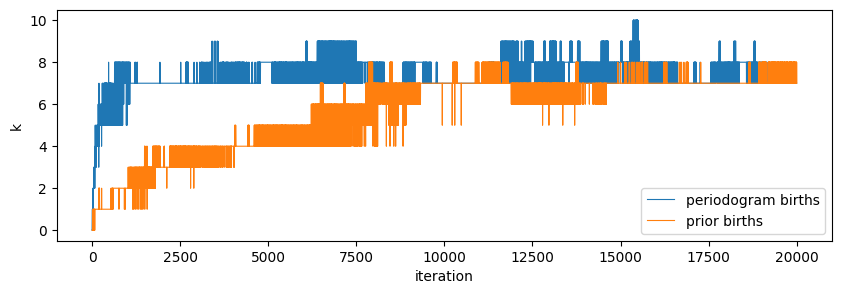

In [13]:
prior_run = make_sampler(prior_births, "chains_rj_prior_births")
prior_run.sample(x0, num_iterations=20_000, initial_k=0)
k_prior_births = prior_run.load_chain()["k"][0]

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(k_cold[:20_000], lw=0.8, label="periodogram births")
ax.plot(k_prior_births, lw=0.8, label="prior births")
ax.set(xlabel="iteration", ylabel="k")
ax.legend();

for name, run, k_run in [
    ("periodogram births", sampler, k_cold),
    ("prior births", prior_run, k_prior_births),
]:
    rate = run.proposal_acceptance_rates()["birth"]["rate"]
    print(f"{name:>18}: birth acceptance {rate:.4f}, k = 7 first at iteration {np.argmax(k_run == 7)}")

Drawn from the prior, births are accepted 0.0206 of the time instead
of 0.0772 (each over its whole run), and the cold chain first reaches
`k = 7` at iteration 6,476 instead of 194: it adds the sinusoids one at
a time over thousands of iterations.

## Where next

- The reversible-jump page of the user guide: custom moves within and
  between models (`add_custom_jump`, `add_model_jump` with a constant
  `log_jacobian`), state-dependent component proposals, checkpointing.
- For galactic binaries, the component proposal is where the
  F-statistic goes, as the periodogram and the residual fit do here.